In [1]:
# Gerekli Kütüphanelerin Yüklenmesi
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings


# Uyarıları kapatmak için (Daha temiz bir çıktı için)
warnings.filterwarnings('ignore')

# Görselleştirme ayarları (Profesyonel görünüm için)
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("Kütüphaneler başarıyla yüklendi.")

Kütüphaneler başarıyla yüklendi.


In [2]:
# 1. VERİ YÜKLEME
# ==========================================
try:
    df = pd.read_csv('data/used_cars.csv')
    print("Veri seti başarıyla yüklendi!")
except FileNotFoundError:
    print("Hata: Dosya bulunamadı. Lütfen dosya yolunu kontrol edin.")

Veri seti başarıyla yüklendi!


In [3]:
# 2. VERİYE İLK BAKIŞ (EDA - Initial Exploration)
# ==========================================

# İlk 5 satırı görüntüleme
print("\n--- Veri Setinin İlk 5 Satırı ---")
display(df.head())

# Veri Setinin Boyutu
print(f"\n--- Veri Seti Boyutu ---")
print(f"Satır Sayısı: {df.shape[0]}")
print(f"Sütun Sayısı: {df.shape[1]}")

# Veri Tipleri ve Bellek Kullanımı
print("\n--- Veri Seti Hakkında Genel Bilgi ---")
df.info()

# Tekrar Eden Verilerin Kontrolü (Duplicates)
duplicate_count = df.duplicated().sum()
print(f"\n--- Tekrar Eden Veri Sayısı ---")
print(f"Toplam Duplicate Satır: {duplicate_count}")


--- Veri Setinin İlk 5 Satırı ---


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"



--- Veri Seti Boyutu ---
Satır Sayısı: 4009
Sütun Sayısı: 12

--- Veri Seti Hakkında Genel Bilgi ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   brand         4009 non-null   object
 1   model         4009 non-null   object
 2   model_year    4009 non-null   int64 
 3   milage        4009 non-null   object
 4   fuel_type     3839 non-null   object
 5   engine        4009 non-null   object
 6   transmission  4009 non-null   object
 7   ext_col       4009 non-null   object
 8   int_col       4009 non-null   object
 9   accident      3896 non-null   object
 10  clean_title   3413 non-null   object
 11  price         4009 non-null   object
dtypes: int64(1), object(11)
memory usage: 376.0+ KB

--- Tekrar Eden Veri Sayısı ---
Toplam Duplicate Satır: 0



--- Sütun Bazlı Eksik Veri Sayıları ---
             Toplam Eksik  Yüzde (%)
clean_title           596  14.866550
fuel_type             170   4.240459
accident              113   2.818658


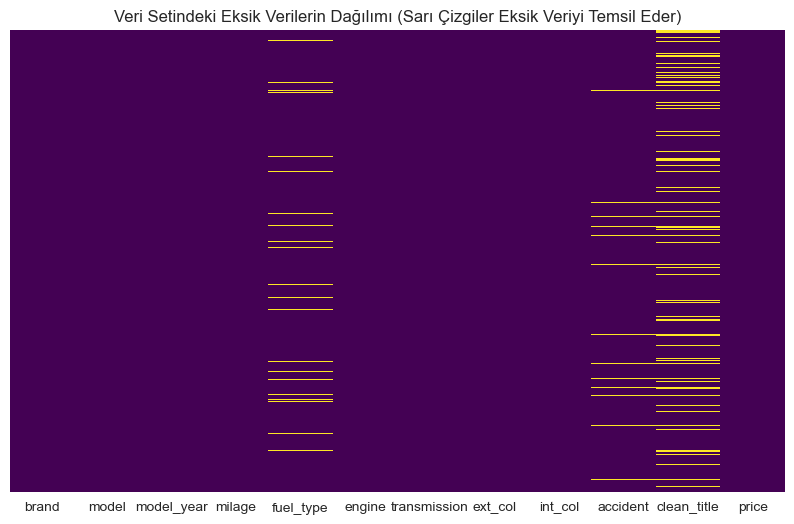

In [4]:
# 3. EKSİK VERİLERİN (MISSING VALUES) ÖZETİ
# ==========================================
print("\n--- Sütun Bazlı Eksik Veri Sayıları ---")
missing_values = df.isnull().sum().sort_values(ascending=False)
missing_percentage = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)

missing_df = pd.concat([missing_values, missing_percentage], axis=1, keys=['Toplam Eksik', 'Yüzde (%)'])
print(missing_df[missing_df['Toplam Eksik'] > 0]) # Sadece eksik verisi olanları göster

# Eksik Veri Görselleştirmesi (Heatmap)
plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Veri Setindeki Eksik Verilerin Dağılımı (Sarı Çizgiler Eksik Veriyi Temsil Eder)')
plt.show()

### Temizleme Aşaması

In [5]:
print("--- Temizleme Öncesi Veri Tipleri ---")
print(df[['price', 'milage']].dtypes)
print("\n" + "="*50 + "\n")

--- Temizleme Öncesi Veri Tipleri ---
price     object
milage    object
dtype: object




In [6]:
# 1. PRICE (FİYAT) SÜTUNUNU TEMİZLEME
# ========================================================
# '$' ve ',' işaretlerini kaldırıp sayıya çeviriyoruz.
# Hata almamak için önce stringe çevirip işlem yapıyoruz.

try:
    df['price'] = df['price'].astype(str).str.replace('$', '', regex=False)
    df['price'] = df['price'].str.replace(',', '', regex=False)
    df['price'] = pd.to_numeric(df['price'], errors='coerce') # Dönüştürülemeyenleri NaN yapar
    
    print(" 'Price' sütunu başarıyla sayısal veriye dönüştürüldü.")
except Exception as e:
    print(f"Price dönüştürme hatası: {e}")

 'Price' sütunu başarıyla sayısal veriye dönüştürüldü.


In [7]:
# 2. MILAGE (KİLOMETRE) SÜTUNUNU TEMİZLEME
# ========================================================
# 'mi.' ve ',' işaretlerini kaldırıyoruz.

try:
    df['milage'] = df['milage'].astype(str).str.replace('mi.', '', regex=False)
    df['milage'] = df['milage'].str.replace(',', '', regex=False)
    df['milage'] = pd.to_numeric(df['milage'], errors='coerce')
    
    print(" 'Milage' sütunu başarıyla sayısal veriye dönüştürüldü.")
except Exception as e:
    print(f"Milage dönüştürme hatası: {e}")


 'Milage' sütunu başarıyla sayısal veriye dönüştürüldü.


In [8]:
print("\n" + "="*50 + "\n")
print("--- Temizleme Sonrası İstatistiksel Özet ---")
print(df[['price', 'milage']].describe())



--- Temizleme Sonrası İstatistiksel Özet ---
              price         milage
count  4.009000e+03    4009.000000
mean   4.455319e+04   64717.551010
std    7.871064e+04   52296.599459
min    2.000000e+03     100.000000
25%    1.720000e+04   23044.000000
50%    3.100000e+04   52775.000000
75%    4.999000e+04   94100.000000
max    2.954083e+06  405000.000000


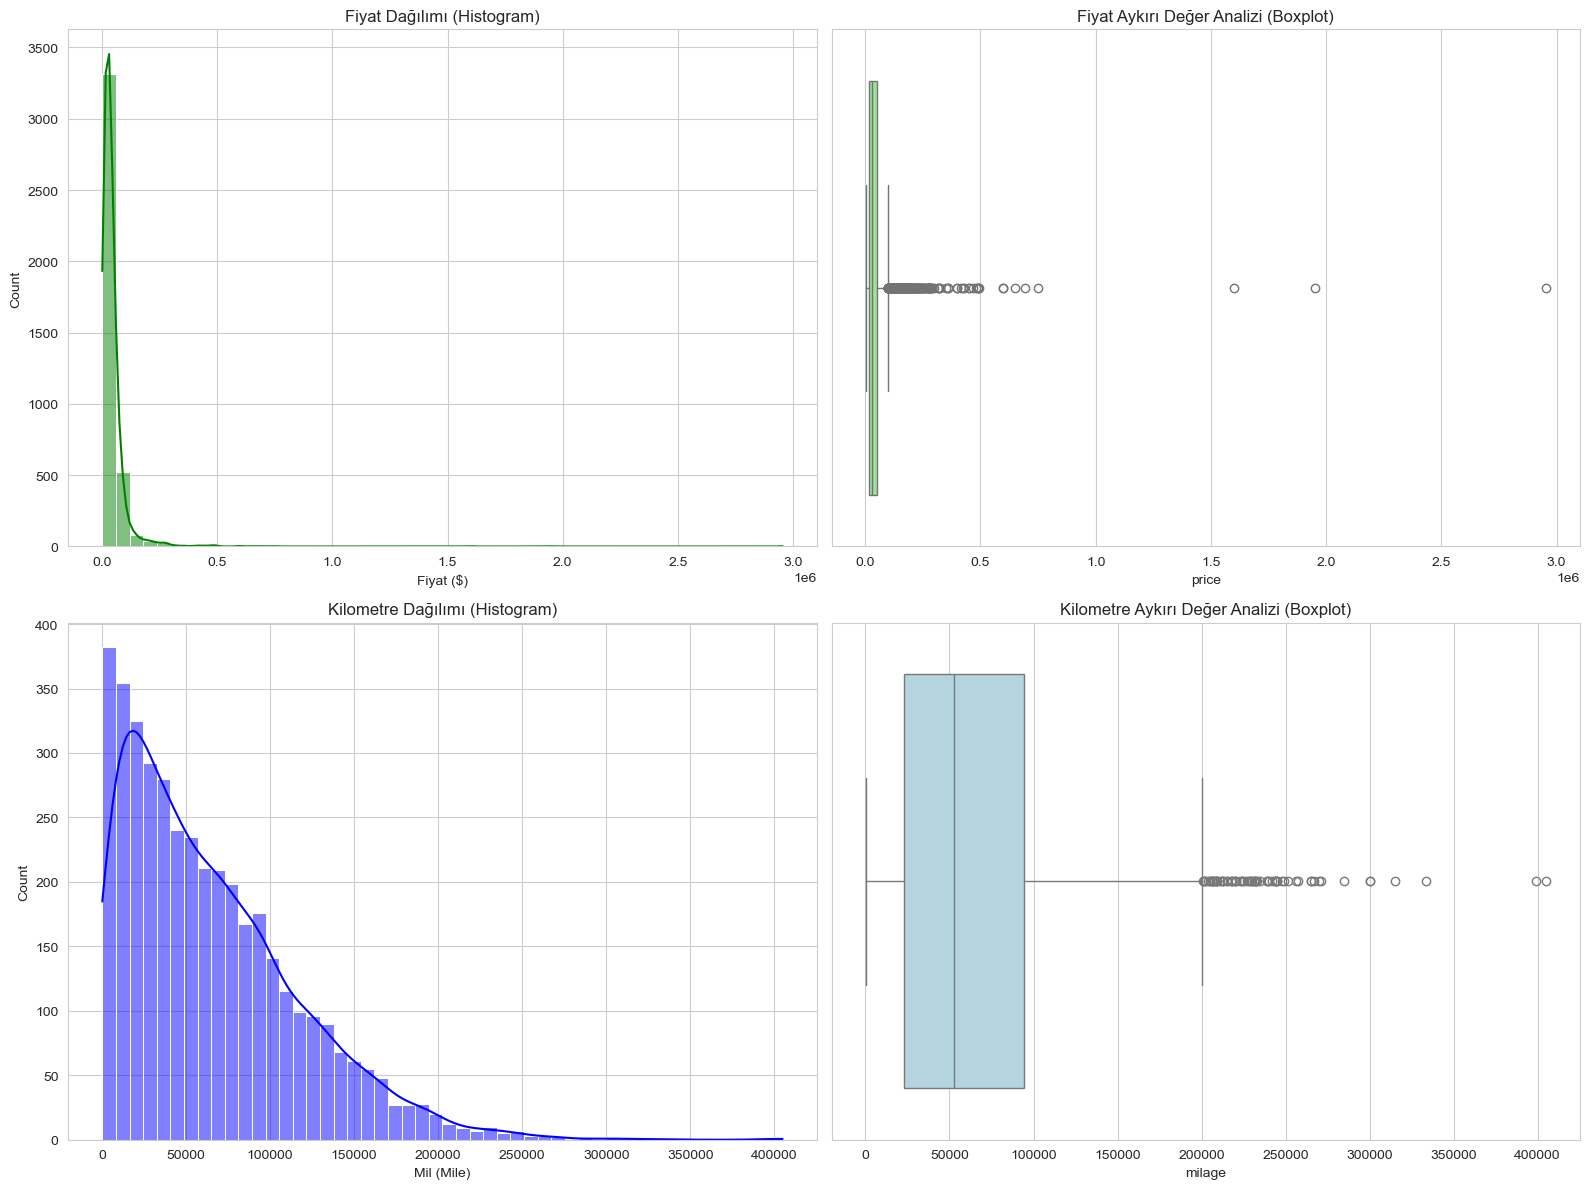

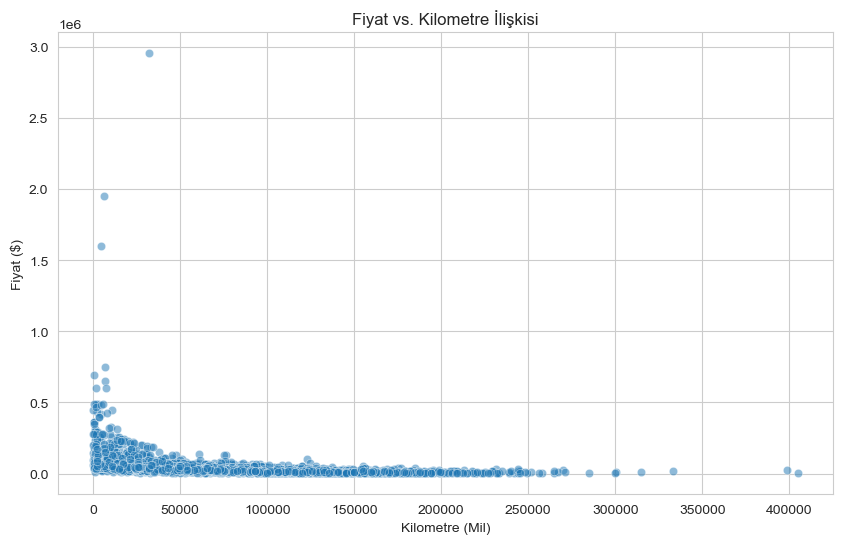

In [9]:
# Grafik Alanı Oluşturma (2 Satır, 2 Sütun)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Fiyat Dağılımı (Histogram)
sns.histplot(df['price'], bins=50, kde=True, color='green', ax=axes[0, 0])
axes[0, 0].set_title('Fiyat Dağılımı (Histogram)')
axes[0, 0].set_xlabel('Fiyat ($)')

# Fiyat Aykırı Değer Analizi (Boxplot)
sns.boxplot(x=df['price'], color='lightgreen', ax=axes[0, 1])
axes[0, 1].set_title('Fiyat Aykırı Değer Analizi (Boxplot)')

# Kilometre Dağılımı (Histogram)
sns.histplot(df['milage'], bins=50, kde=True, color='blue', ax=axes[1, 0])
axes[1, 0].set_title('Kilometre Dağılımı (Histogram)')
axes[1, 0].set_xlabel('Mil (Mile)')

# Kilometre Aykırı Değer Analizi (Boxplot)
sns.boxplot(x=df['milage'], color='lightblue', ax=axes[1, 1])
axes[1, 1].set_title('Kilometre Aykırı Değer Analizi (Boxplot)')

plt.tight_layout()
plt.show()

# Fiyat ve Kilometre Arasındaki İlişki (Scatter Plot)
plt.figure(figsize=(10, 6))
sns.scatterplot(x='milage', y='price', data=df, alpha=0.5)
plt.title('Fiyat vs. Kilometre İlişkisi')
plt.xlabel('Kilometre (Mil)')
plt.ylabel('Fiyat ($)')
plt.show()

## FUEL

In [10]:
print("--- Ham Fuel_Type (Yakıt) Verisi ---")
print(f"Benzersiz Değer Sayısı: {df['fuel_type'].nunique()}")
print(f"Eksik Veri Sayısı: {df['fuel_type'].isnull().sum()}")
print("\nEn Sık Görülen 10 Değer:")
print(df['fuel_type'].value_counts().head(10))
print("\n" + "="*50 + "\n")

--- Ham Fuel_Type (Yakıt) Verisi ---
Benzersiz Değer Sayısı: 7
Eksik Veri Sayısı: 170

En Sık Görülen 10 Değer:
fuel_type
Gasoline          3309
Hybrid             194
E85 Flex Fuel      139
Diesel             116
–                   45
Plug-In Hybrid      34
not supported        2
Name: count, dtype: int64




In [11]:

print(f"Toplam Eksik (NaN): {df['fuel_type'].isnull().sum()}")
print("Örnek Eksik Veriler (Markalar):")
print(df[df['fuel_type'].isnull()]['brand'].unique())
print("\n" + "="*50 + "\n")

Toplam Eksik (NaN): 170
Örnek Eksik Veriler (Markalar):
['Tesla' 'Lucid' 'Rivian' 'Polestar' 'Mercedes-Benz' 'Chevrolet' 'Ford'
 'Audi' 'Kia' 'Nissan' 'Karma' 'FIAT' 'Volvo' 'BMW' 'Hyundai' 'Toyota'
 'Porsche' 'Cadillac' 'Volkswagen' 'GMC']




In [ ]:
# 1. AKILLI YAKIT SINIFLANDIRMA (SMART CLASSIFICATION)
# ========================================================

# Sadece elektrikli araç üreten markalar listesi
# Bu markaları görürsek direkt 'Electric' etiketi basacağız.
EV_BRANDS = ['Tesla', 'Rivian', 'Lucid', 'Polestar', 'Fisker', 'Karma']

def classify_fuel_smart(row):
    # Verileri küçük harfe çevirip string yapalım
    brand = str(row['brand'])
    fuel = str(row['fuel_type']).lower()
    engine = str(row['engine']).lower()
    model = str(row['model']).lower()
    
    # KURAL 1: MARKA BAZLI KESİN ATAMA
    # Eğer marka Tesla, Rivian vb. ise tartışmasız Elektriktir.
    if brand in EV_BRANDS:
        return 'Electric'
    
    # KURAL 2: HİBRİT KONTROLÜ (Öncelikli)
    # Hem elektrik hem benzin kelimesi geçiyorsa Hibrittir.
    if ('hybrid' in fuel) or ('hybrid' in engine) or ('plug-in' in fuel):
        return 'Hybrid'
    
    # KURAL 3: ELEKTRİK KELİME KONTROLÜ
    # Marka listede yok ama motor bilgisinde 'Electric' yazıyor olabilir.
    if 'electric' in fuel or 'electric' in engine or 'battery' in engine:
        return 'Electric'
        
    # KURAL 4: DİĞER YAKITLAR
    if 'diesel' in fuel:
        return 'Diesel'
    if 'e85' in fuel or 'flex' in fuel:
        return 'E85 Flex Fuel'
    if 'gas' in fuel or 'petrol' in fuel:
        return 'Gasoline'
    
    # KURAL 5: HALA BULAMADIKLARIMIZ
    # Eğer fuel_type NaN ise ve yukarıdakilere girmediyse
    if pd.isna(row['fuel_type']) or row['fuel_type'] == 'nan':
        return 'Unknown'
        
    return 'Gasoline' # Varsayılan olarak en yaygın yakıtı atayabiliriz veya 'Other' diyebiliriz.

# Fonksiyonu satır satır (axis=1) uyguluyoruz
df['fuel_category'] = df.apply(classify_fuel_smart, axis=1)

In [13]:
# Unknown kalanları en çok tekrar eden (Mod) ile doldurma (Opsiyonel, şu an analiz için bırakabiliriz)
# df['fuel_category'] = df['fuel_category'].replace('Unknown', df['fuel_category'].mode()[0])

print("--- Akıllı Sınıflandırma Sonrası Dağılım ---")
print(df['fuel_category'].value_counts())

# Kontrol: Tesla araçları ne olarak etiketlendi?
print("\n--- Tesla Marka Araçların Yakıt Etiketleri ---")
print(df[df['brand'] == 'Tesla'][['brand', 'model', 'fuel_type', 'fuel_category']].head())

print("\n" + "="*50 + "\n")

--- Akıllı Sınıflandırma Sonrası Dağılım ---
fuel_category
Gasoline         3354
Hybrid            228
Electric          171
E85 Flex Fuel     139
Diesel            116
Unknown             1
Name: count, dtype: int64

--- Tesla Marka Araçların Yakıt Etiketleri ---
     brand                        model fuel_type fuel_category
9    Tesla      Model X Long Range Plus       NaN      Electric
155  Tesla          Model 3 Performance       NaN      Electric
189  Tesla          Model Y Performance       NaN      Electric
225  Tesla                 Model X Base       NaN      Electric
298  Tesla  Model 3 Standard Range Plus       NaN      Electric




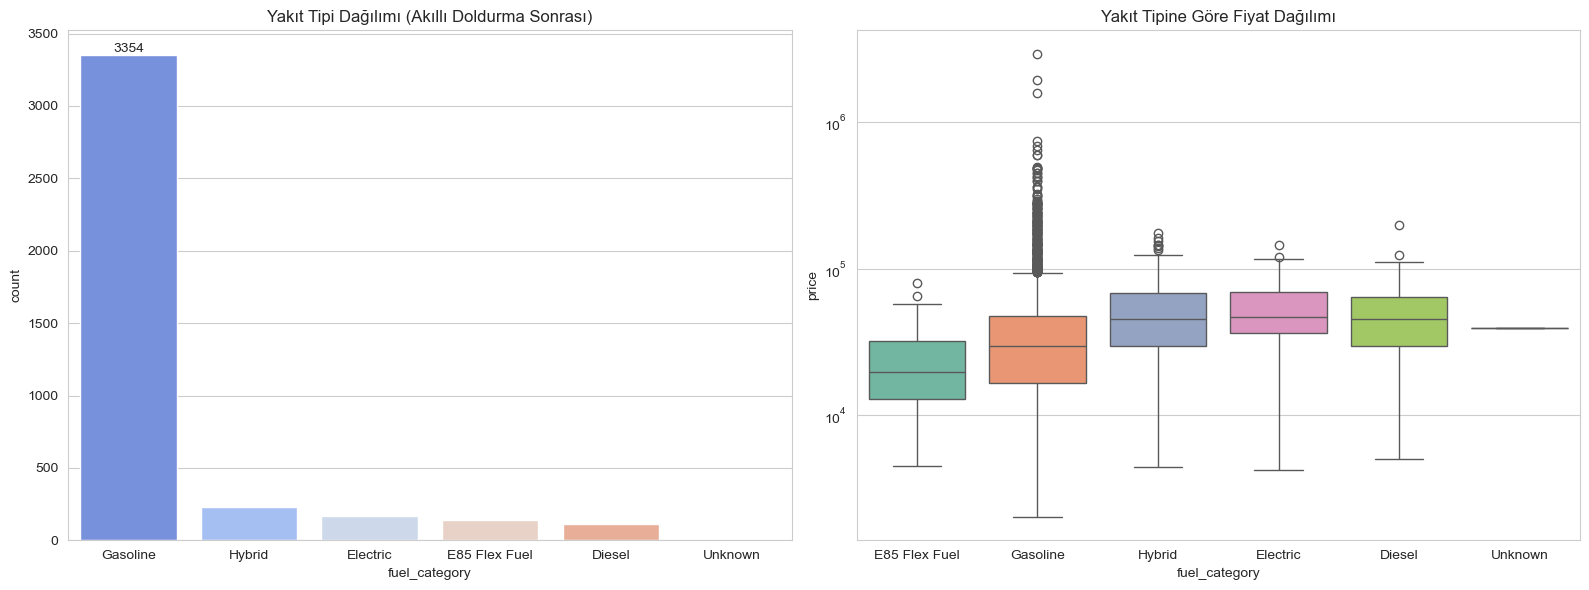

In [ ]:
# 2. GÖRSELLEŞTİRME
# ========================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Adet Dağılımı
sns.countplot(x='fuel_category', data=df, palette='coolwarm', order=df['fuel_category'].value_counts().index, ax=axes[0])
axes[0].set_title('Yakıt Tipi Dağılımı (Akıllı Doldurma Sonrası)')
axes[0].bar_label(axes[0].containers[0])

# Fiyat Dağılımı
sns.boxplot(x='fuel_category', y='price', data=df, palette='Set2', ax=axes[1])
axes[1].set_title('Yakıt Tipine Göre Fiyat Dağılımı')
axes[1].set_yscale('log')

plt.tight_layout()
plt.show()

In [ ]:
# 3. İSTATİSTİKSEL ÖZET
# ========================================================
summary = df.groupby('fuel_category')[['price', 'milage']].agg(['mean', 'median', 'count', 'min', 'max'])
display(summary.round(0))

price                                   milage           \
                  mean   median count    min      max      mean   median   
fuel_category                                                              
Diesel         48695.0  45450.0   116   5000   200000   92862.0  80350.0   
E85 Flex Fuel  22744.0  19500.0   139   4500    79950  104914.0  98000.0   
Electric       54031.0  46998.0   171   4200   146000   25688.0  18000.0   
Gasoline       44421.0  29799.0  3354   2000  2954083   65691.0  54950.0   
Hybrid         50609.0  44998.0   228   4400   175000   41069.0  25330.0   
Unknown        38998.0  38998.0     1  38998    38998   11945.0  11945.0   

                                    
              count    min     max  
fuel_category                       
Diesel          116    100  399000  
E85 Flex Fuel   139  19000  248000  
Electric        171    159  103000  
Gasoline       3354    115  405000  
Hybrid          228    200  264893  
Unknown           1  11945   11945

In [16]:
display(df.head())

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,fuel_category
0,Ford,Utility Police Interceptor Base,2013,51000,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300,E85 Flex Fuel
1,Hyundai,Palisade SEL,2021,34742,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005,Gasoline
2,Lexus,RX 350 RX 350,2022,22372,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598,Gasoline
3,INFINITI,Q50 Hybrid Sport,2015,88900,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500,Hybrid
4,Audi,Q3 45 S line Premium Plus,2021,9835,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999,Gasoline


## Transmission

--- Ham Vites Verisi İncelemesi ---
Toplam Farklı Vites Tanımı Sayısı: 62
Örnek Karmaşık Veriler:
['6-Speed A/T' '8-Speed Automatic' 'Automatic' '7-Speed A/T' 'F' 'A/T'
 '8-Speed A/T' 'Transmission w/Dual Shift Mode' '9-Speed Automatic'
 '6-Speed M/T']


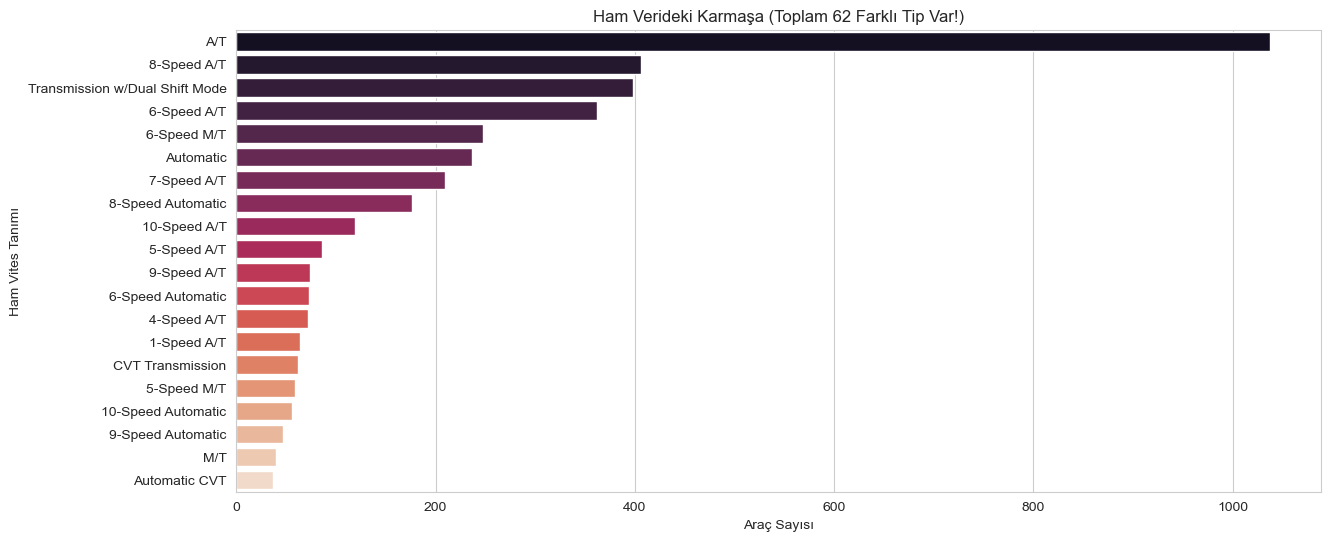

In [17]:
# ========================================================
# BÖLÜM 1: KAOSU GÖSTER (HAM VERİ ANALİZİ)
# ========================================================
print("--- Ham Vites Verisi İncelemesi ---")
print(f"Toplam Farklı Vites Tanımı Sayısı: {df['transmission'].nunique()}")
print("Örnek Karmaşık Veriler:")
print(df['transmission'].unique()[:10])

# Görselleştirme: En sık geçen ilk 20 karmaşık ifade
top_20_raw = df['transmission'].value_counts().head(20)

plt.figure(figsize=(14, 6))
sns.barplot(x=top_20_raw.values, y=top_20_raw.index, palette='rocket')
plt.title(f"Ham Verideki Karmaşa (Toplam {df['transmission'].nunique()} Farklı Tip Var!)")
plt.xlabel('Araç Sayısı')
plt.ylabel('Ham Vites Tanımı')
plt.show()

In [ ]:
# ========================================================
# BÖLÜM 2: TEMİZLEME KURALLARI
# ========================================================
# Karmaşayı çözmek için akıllı algoritma

EV_BRANDS = ['Tesla', 'Rivian', 'Lucid', 'Polestar', 'Fisker', 'Karma']

# 1. yakıtı belirleme (Yardımcı fonksiyon)
def classify_fuel_helper(row):
    brand = str(row['brand'])
    fuel = str(row['fuel_type']).lower()
    engine = str(row['engine']).lower()
    if brand in EV_BRANDS: return 'Electric'
    if 'hybrid' in fuel or 'hybrid' in engine: return 'Hybrid'
    if 'electric' in fuel or 'battery' in engine: return 'Electric'
    return 'Gasoline'

df['fuel_category'] = df.apply(classify_fuel_helper, axis=1)

# 2. Vites Temizleme Fonksiyonu
def clean_transmission_advanced(row):
    text = str(row['transmission']).upper()
    fuel = row['fuel_category']
    
    # Kural 1: Elektrikli -> Single-Speed
    if fuel == 'Electric':
        return 'Single-Speed'
    # Kural 2: Manuel
    if 'MANUAL' in text or 'M/T' in text or 'MT' in text:
        return 'Manual'
    # Kural 3: CVT
    if 'CVT' in text:
        return 'CVT'
    # Kural 4: Yarı Otomatik (DCT/Dual Shift)
    if 'DUAL SHIFT' in text or 'DCT' in text or 'SEMI' in text or 'PDK' in text or 'DSG' in text:
        return 'Semi-Auto'
    # Kural 5: Diğerleri Otomatik
    return 'Automatic'

# Fonksiyonu çalıştırma
df['transmission_type'] = df.apply(clean_transmission_advanced, axis=1)


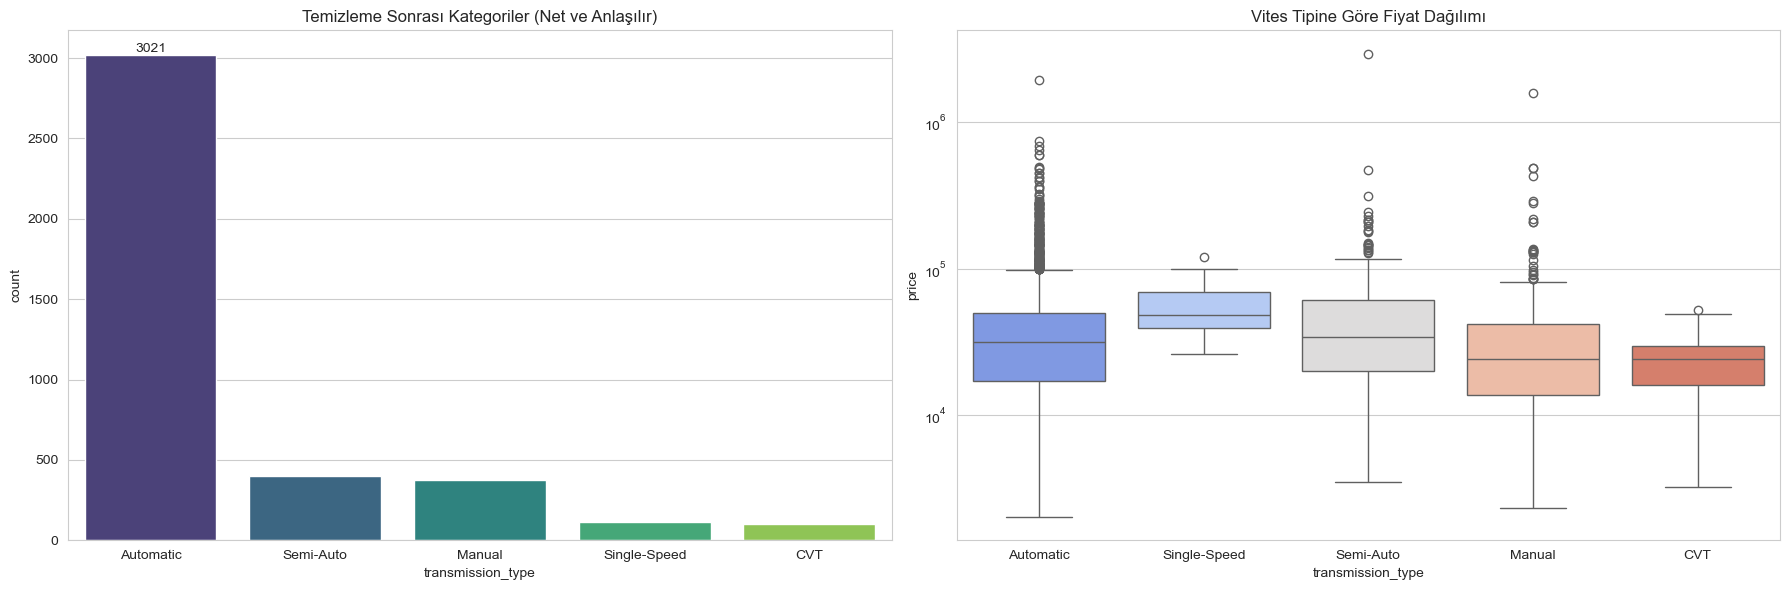

In [ ]:
# ========================================================
# BÖLÜM 3: TEMİZ VERİ ANALİZİ
# ========================================================

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# 1. Grafik: Temizlenmiş Dağılım
order = df['transmission_type'].value_counts().index
sns.countplot(x='transmission_type', data=df, palette='viridis', order=order, ax=axes[0])
axes[0].set_title('Temizleme Sonrası Kategoriler (Net ve Anlaşılır)')
axes[0].bar_label(axes[0].containers[0])

# 2. Grafik: Fiyat Etkisi
sns.boxplot(x='transmission_type', y='price', data=df, palette='coolwarm', ax=axes[1])
axes[1].set_title('Vites Tipine Göre Fiyat Dağılımı')
axes[1].set_yscale('log')

plt.tight_layout()
plt.show()

In [20]:
# İstatistiksel Kanıt
print("\n--- Temizlik Sonrası Özet ---")
print(df['transmission_type'].value_counts())


--- Temizlik Sonrası Özet ---
transmission_type
Automatic       3021
Semi-Auto        400
Manual           376
Single-Speed     112
CVT              100
Name: count, dtype: int64


In [21]:
display(df.groupby('transmission_type')[['price', 'milage']].agg(['mean', 'median', 'count', 'min', 'max']).round(0))

price                                  milage           \
                      mean   median count    min      max     mean   median   
transmission_type                                                             
Automatic          43778.0  31331.0  3021   2000  1950995  66303.0  54000.0   
CVT                23529.0  23948.0   100   3200    52000  63136.0  49324.0   
Manual             41448.0  24000.0   376   2300  1599000  69486.0  61934.0   
Semi-Auto          55222.0  34125.0   400   3500  2954083  58727.0  50700.0   
Single-Speed       56544.0  48000.0   112  25900   119999  28756.0  22028.0   

                                       
                  count   min     max  
transmission_type                      
Automatic          3021   100  399000  
CVT                 100  1094  405000  
Manual              376   265  267000  
Semi-Auto           400   124  206000  
Single-Speed        112   159  103000

In [22]:
display(df.head())

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,fuel_category,transmission_type
0,Ford,Utility Police Interceptor Base,2013,51000,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300,Gasoline,Automatic
1,Hyundai,Palisade SEL,2021,34742,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005,Gasoline,Automatic
2,Lexus,RX 350 RX 350,2022,22372,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598,Gasoline,Automatic
3,INFINITI,Q50 Hybrid Sport,2015,88900,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500,Hybrid,Automatic
4,Audi,Q3 45 S line Premium Plus,2021,9835,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999,Gasoline,Automatic


### Engine

In [ ]:
# BÖLÜM 1:  MOTOR ANALİZİ İÇİN YAKIT TÜRÜNE DİKKAT---
# Önceki adımlarda belirlediğimiz akıllı yakıt sınıflandırmasını uygulama.
EV_BRANDS = ['Tesla', 'Rivian', 'Lucid', 'Polestar', 'Fisker', 'Karma']
def classify_fuel_helper(row):
    brand = str(row['brand'])
    fuel = str(row['fuel_type']).lower()
    engine = str(row['engine']).lower()
    if brand in EV_BRANDS: return 'Electric'
    if 'hybrid' in fuel or 'hybrid' in engine: return 'Hybrid'
    if 'electric' in fuel or 'battery' in engine: return 'Electric'
    if 'diesel' in fuel: return 'Diesel'
    return 'Gasoline'

df['fuel_category'] = df.apply(classify_fuel_helper, axis=1)

In [ ]:
# ========================================================
# BÖLÜM 2: HAM VERİ ANALİZİ 
# ========================================================
print("--- 1. HAM ENGINE (MOTOR) VERİ ANALİZİ ---")
unique_engines = df['engine'].nunique()
missing_engines = df['engine'].isnull().sum()
print(f"Toplam Benzersiz Motor Metni Sayısı: {unique_engines}")
print(f"Eksik (Null) Motor Verisi: {missing_engines}")
print("\nEn Sık Karşılaşılan 5 Karmaşık Veri:")
print(df['engine'].value_counts().head(5))

--- 1. HAM ENGINE (MOTOR) VERİ ANALİZİ ---
Toplam Benzersiz Motor Metni Sayısı: 1146
Eksik (Null) Motor Verisi: 0

En Sık Karşılaşılan 5 Karmaşık Veri:
engine
2.0L I4 16V GDI DOHC Turbo                               52
355.0HP 5.3L 8 Cylinder Engine Gasoline Fuel             48
420.0HP 6.2L 8 Cylinder Engine Gasoline Fuel             47
–                                                        45
300.0HP 3.0L Straight 6 Cylinder Engine Gasoline Fuel    44
Name: count, dtype: int64


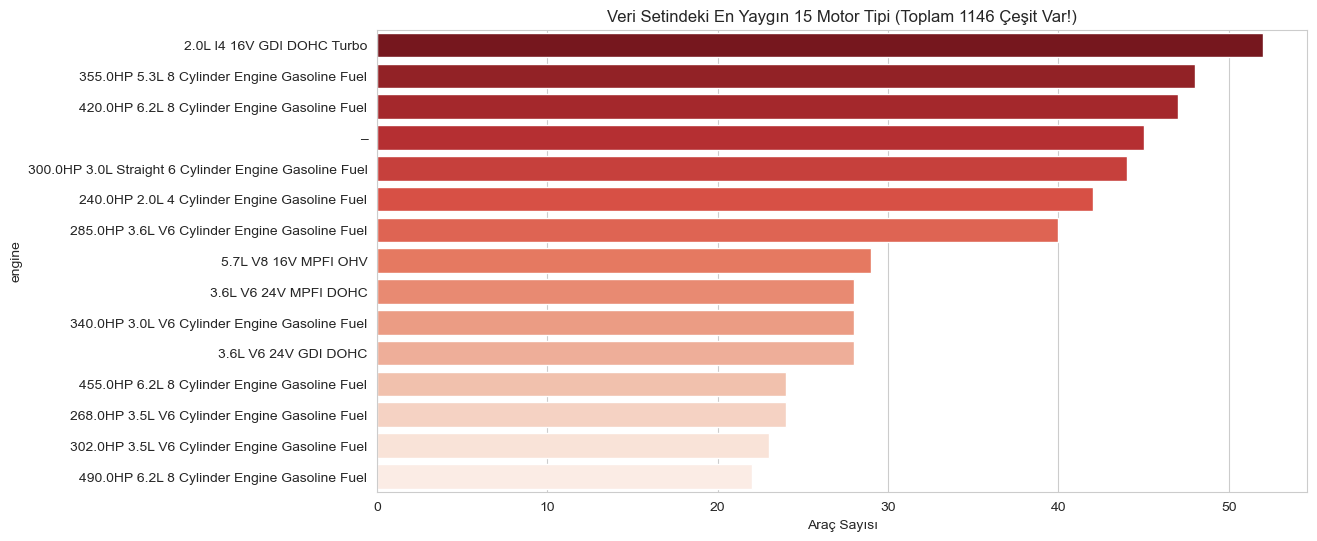

In [ ]:
# Görselleştirme
top_15_engine = df['engine'].value_counts().head(15)
plt.figure(figsize=(12, 6))
sns.barplot(x=top_15_engine.values, y=top_15_engine.index, palette='Reds_r')
plt.title(f'Veri Setindeki En Yaygın 15 Motor Tipi (Toplam {unique_engines} Çeşit Var!)')
plt.xlabel('Araç Sayısı')
plt.show()

In [ ]:
# ========================================================
# BÖLÜM 3: TEMİZLİK VE AYRIŞTIRMA 
# ========================================================
# Burada Regex ve Mantıksal Kurallar devreye giriyor.

def extract_engine_features(row):
    text = str(row['engine'])
    fuel = row['fuel_category']
    
    # Başlangıç değerleri
    hp, liters, cylinders = None, None, None
    
    # 1. Beygir Gücü (HP) - Her araçta aranır
    # Örn: "300.0HP" ifadesini yakalar
    hp_match = re.search(r'(\d+\.?\d*)HP', text)
    if hp_match:
        hp = float(hp_match.group(1))
        
    # 2. Motor Hacmi ve Silindir (Yakıta Göre Değişir)
    if fuel == 'Electric':
        # Elektrikli araçlarda litre ve silindir 0 kabul edilir.
        liters = 0.0
        cylinders = 0.0
    else:
        # İçten yanmalı araçlarda Litre ve Silindir aranır
        
        # Litre (Örn: 3.5L)
        liters_match = re.search(r'(\d+\.?\d*)\s*L', text)
        if liters_match:
            liters = float(liters_match.group(1))
            
        # Silindir (Örn: V6, 6 Cylinder)
        cyl_match = re.search(r'V(\d+)', text)
        if not cyl_match:
            cyl_match = re.search(r'(\d+)\s*Cylinder', text)
        
        if cyl_match:
            cylinders = int(cyl_match.group(1))
            
    return pd.Series([hp, liters, cylinders])

# Fonksiyonu uygulama
print("\n--- 2. ÖZELLİK ÇIKARIMI (FEATURE EXTRACTION) YAPILIYOR ---")
df[['horsepower', 'engine_volume', 'cylinders']] = df.apply(extract_engine_features, axis=1)
print("İşlem Tamamlandı. Metinler sayılara dönüştürüldü.")



--- 2. ÖZELLİK ÇIKARIMI (FEATURE EXTRACTION) YAPILIYOR ---
İşlem Tamamlandı. Metinler sayılara dönüştürüldü.



--- 3. YENİ SÜTUNLARIN İSTATİSTİKLERİ ---
       horsepower  engine_volume  cylinders
count      3201.0         3902.0     3499.0
mean        332.2            3.6        6.1
std         122.3            1.5        2.0
min          70.0            0.0        0.0
25%         248.0            2.5        5.0
50%         310.0            3.5        6.0
75%         400.0            4.6        8.0
max        1020.0            8.4       12.0


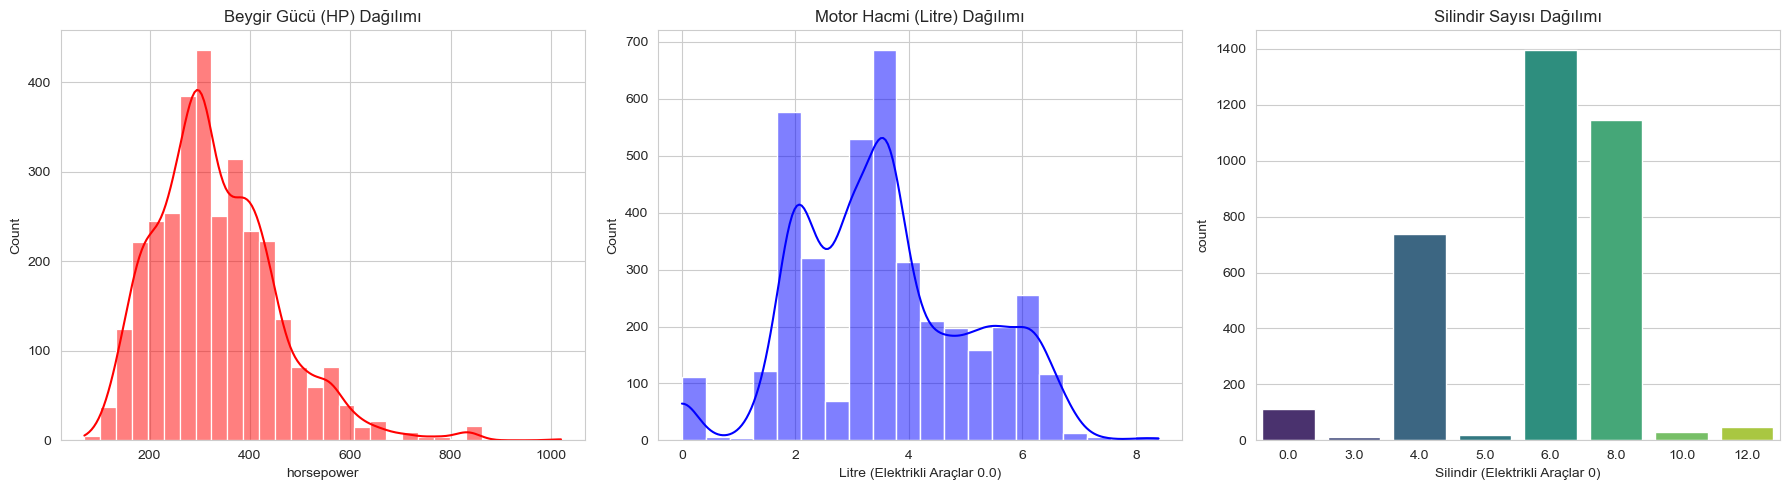

In [ ]:
# ========================================================
# BÖLÜM 4: SONUÇ ANALİZİ VE KARŞILAŞTIRMA
# ========================================================

# İstatistiksel Özet
print("\n--- 3. YENİ SÜTUNLARIN İSTATİSTİKLERİ ---")
print(df[['horsepower', 'engine_volume', 'cylinders']].describe().round(1))

# Görselleştirme: Temiz Verinin Dağılımı
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Beygir Gücü
sns.histplot(df['horsepower'], bins=30, kde=True, color='red', ax=axes[0])
axes[0].set_title('Beygir Gücü (HP) Dağılımı')

# Motor Hacmi
sns.histplot(df['engine_volume'], bins=20, kde=True, color='blue', ax=axes[1])
axes[1].set_title('Motor Hacmi (Litre) Dağılımı')
axes[1].set_xlabel('Litre (Elektrikli Araçlar 0.0)')

# Silindir Sayısı
sns.countplot(x='cylinders', data=df, palette='viridis', ax=axes[2])
axes[2].set_title('Silindir Sayısı Dağılımı')
axes[2].set_xlabel('Silindir (Elektrikli Araçlar 0)')

plt.tight_layout()
plt.show()

In [ ]:
# ========================================================
# BÖLÜM 5: EKSİK VERİ KONTROLÜ (YENİ DEĞERLER)
# ========================================================
print("\n--- 4. YENİ OLUŞAN SÜTUNLARDAKİ EKSİK VERİ SAYILARI ---")
null_counts = df[['horsepower', 'engine_volume', 'cylinders']].isnull().sum()
print(null_counts)

print("\nNOT: Bu eksik veriler, metin içinde 'HP', 'L' veya 'Cylinder' yazmayan satırlardır.")
print("Bir sonraki adımda bunları akıllıca dolduracağız (Imputation).")


--- 4. YENİ OLUŞAN SÜTUNLARDAKİ EKSİK VERİ SAYILARI ---
horsepower       808
engine_volume    107
cylinders        510
dtype: int64

NOT: Bu eksik veriler, metin içinde 'HP', 'L' veya 'Cylinder' yazmayan satırlardır.
Bir sonraki adımda bunları akıllıca dolduracağız (Imputation).


 "Eksik verileri rastgele değil önce o aracın modeline bakıp daha sonra yoksa markasına bakılır. Böylece verinin doğal yapısı bozulmaz."

In [ ]:
# ========================================================
# BÖLÜM 6:. AKILLI DOLDURMA (IMPUTATION)
# ========================================================
print("--- Doldurma İşlemi Başlıyor ---")
cols_to_fill = ['horsepower', 'engine_volume', 'cylinders']

# Karşılaştırma yapabilmek için orijinal veriyi kopyalama
df_original = df[cols_to_fill].copy()

print(f"Başlangıçtaki Eksik Veriler:\n{df[cols_to_fill].isnull().sum()}")

# DÖNGÜ: Her sütun için aşamalı doldurma
for col in cols_to_fill:
    # Adım 1: Aynı MODELdeki araçların medyanını al (En hassas tahmin)
    # Örn: 'Ford F-150' eksikse, diğer 'Ford F-150'lerin ortalamasını bas.
    df[col] = df[col].fillna(df.groupby('model')[col].transform('median'))
    
    # Adım 2: Hala boşsa, aynı MARKAdaki araçların medyanını al
    # Örn: Modelden bulamadık, 'Ford' markasının genel ortalamasını bas.
    df[col] = df[col].fillna(df.groupby('brand')[col].transform('median'))
    
    # Adım 3: Çok nadir durumlarda hala boşsa, genel medyanı bas
    df[col] = df[col].fillna(df[col].median())

print(f"\nİşlem Sonrası Eksik Veriler:\n{df[cols_to_fill].isnull().sum()}")

--- Doldurma İşlemi Başlıyor ---
Başlangıçtaki Eksik Veriler:
horsepower       808
engine_volume    107
cylinders        510
dtype: int64

İşlem Sonrası Eksik Veriler:
horsepower       0
engine_volume    0
cylinders        0
dtype: int64


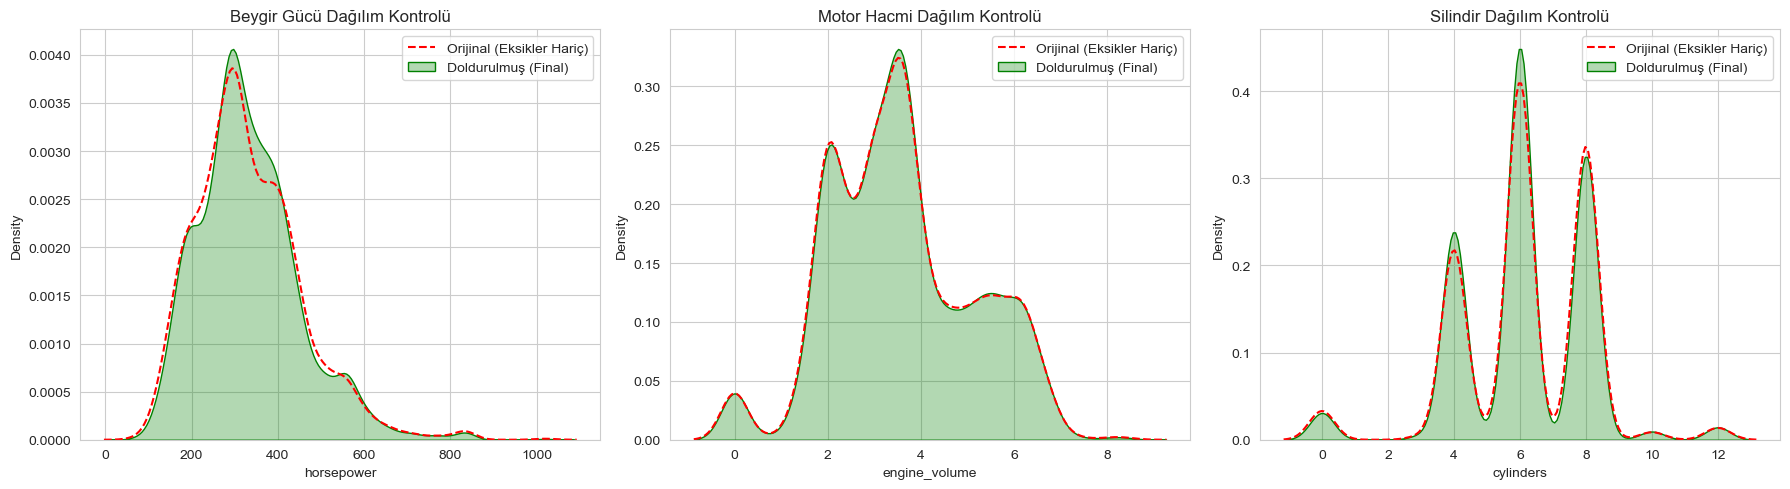

In [ ]:
# ========================================================
# BÖLÜM 7: GÖRSEL KARŞILAŞTIRMA
# ========================================================
# Burada amacımız, doldurma işleminin verinin dağılımını bozmadığını ispatlamak.

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_titles = [('horsepower', 'Beygir Gücü'), ('engine_volume', 'Motor Hacmi'), ('cylinders', 'Silindir')]

for i, (col, title) in enumerate(plot_titles):
    # Orijinal Veri (Kırmızı Çizgili) - Sadece mevcut veriler
    sns.kdeplot(df_original[col].dropna(), ax=axes[i], color='red', linestyle='--', label='Orijinal (Eksikler Hariç)')
    
    # Doldurulmuş Veri (Yeşil Dolgulu)
    sns.kdeplot(df[col], ax=axes[i], color='green', fill=True, alpha=0.3, label='Doldurulmuş (Final)')
    
    axes[i].set_title(f'{title} Dağılım Kontrolü')
    axes[i].legend()

plt.tight_layout()
plt.show()

In [31]:
# İstatistiksel Sağlama
print("\n--- İstatistiksel Kontrol (Sapma Var mı?) ---")
comparison = pd.DataFrame({
    'Orijinal Ort': df_original.mean(),
    'Yeni Ort': df[cols_to_fill].mean(),
    'Fark': df[cols_to_fill].mean() - df_original.mean()
})
print(comparison.round(3))


--- İstatistiksel Kontrol (Sapma Var mı?) ---
               Orijinal Ort  Yeni Ort   Fark
horsepower          332.206   333.262  1.055
engine_volume         3.580     3.581  0.002
cylinders             6.135     6.088 -0.047


### accident ve clean_title

In [ ]:
# ========================================================
# BÖLÜM 8: HAM VERİ ANALİZİ
# ========================================================
print("--- 1. Accident (Kaza) Sütunu ---")
print(df['accident'].value_counts(dropna=False))

print("\n--- 2. Clean Title (Temiz Belge) Sütunu ---")
print(df['clean_title'].value_counts(dropna=False))
print(f"Clean Title Eksik Veri Sayısı: {df['clean_title'].isnull().sum()}")

--- 1. Accident (Kaza) Sütunu ---
accident
None reported                             2910
At least 1 accident or damage reported     986
NaN                                        113
Name: count, dtype: int64

--- 2. Clean Title (Temiz Belge) Sütunu ---
clean_title
Yes    3413
NaN     596
Name: count, dtype: int64
Clean Title Eksik Veri Sayısı: 596


In [ ]:
# ========================================================
# BÖLÜM 9: DÖNÜŞÜM VE ENCODING (0-1 DÖNÜŞÜMÜ)
# ========================================================

# 1. Accident Dönüşümü
# "None reported" -> 0 (Kaza Yok)
# "At least 1 accident..." -> 1 (Kaza Var)
# Eksik veri varsa (NaN), riskli olduğu için 1 kabul edilebilir veya moda göre doldurulabilir.


def clean_accident(text):
    if pd.isna(text): return 0 # Bilinmiyorsa temiz varsayalım (veya analize göre değişir)
    if 'None reported' in str(text):
        return 0
    else:
        return 1 # Kaza var

df['accident_binary'] = df['accident'].apply(clean_accident)

# 2. Clean Title Dönüşümü
# "Yes" -> 1 (Belge Temiz)
# NaN -> 0 (Belge Temiz Değil / Bilinmiyor / Riskli)
# Not: İlanlarda genelde "Clean Title" ise işaretlenir, değilse boş bırakılır.
# Bu yüzden boşları 0 (Riskli) kabul etmek mantıklı bir yaklaşımdır.

df['clean_title_binary'] = df['clean_title'].apply(lambda x: 1 if str(x) == 'Yes' else 0)
# ========================================================
print("\n--- Dönüşüm Sonrası Özet ---")
print("Kaza Durumu (1: Var, 0: Yok):")
print(df['accident_binary'].value_counts())
print("\nTemiz Belge (1: Evet, 0: Hayır/Bilinmiyor):")
print(df['clean_title_binary'].value_counts())


--- Dönüşüm Sonrası Özet ---
Kaza Durumu (1: Var, 0: Yok):
accident_binary
0    3023
1     986
Name: count, dtype: int64

Temiz Belge (1: Evet, 0: Hayır/Bilinmiyor):
clean_title_binary
1    3413
0     596
Name: count, dtype: int64


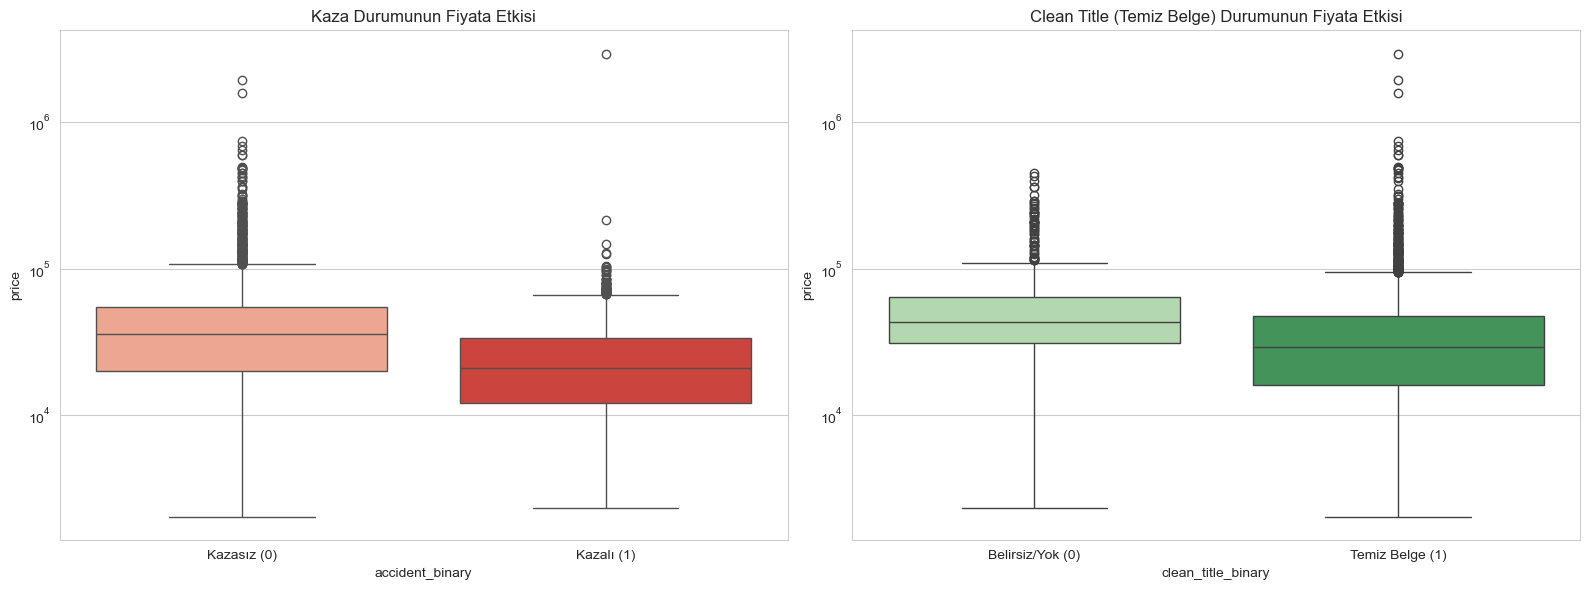

In [ ]:
# ========================================================
# BÖLÜM 10: GÖRSELLEŞTİRME VE FİYAT ETKİSİ
# ========================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Grafik 1: Kaza Durumunun Fiyata Etkisi
sns.boxplot(x='accident_binary', y='price', data=df, palette='Reds', ax=axes[0])
axes[0].set_title('Kaza Durumunun Fiyata Etkisi')
axes[0].set_xticklabels(['Kazasız (0)', 'Kazalı (1)'])
axes[0].set_yscale('log')

# Grafik 2: Clean Title Durumunun Fiyata Etkisi
sns.boxplot(x='clean_title_binary', y='price', data=df, palette='Greens', ax=axes[1])
axes[1].set_title('Clean Title (Temiz Belge) Durumunun Fiyata Etkisi')
axes[1].set_xticklabels(['Belirsiz/Yok (0)', 'Temiz Belge (1)'])
axes[1].set_yscale('log')

plt.tight_layout()
plt.show()

In [35]:
# İstatistiksel Kanıt (Ortalama Fiyat Farkları)
print("\n--- Fiyat Analizi ---")
acc_price = df.groupby('accident_binary')['price'].median()
title_price = df.groupby('clean_title_binary')['price'].median()

print(f"Kazasız Araç Medyan Fiyatı: ${acc_price[0]:,.0f}")
print(f"Kazalı Araç Medyan Fiyatı:  ${acc_price[1]:,.0f}")
print(f"--> Kaza, fiyatı ortalama %{((acc_price[0]-acc_price[1])/acc_price[0]*100):.1f} düşürüyor.\n")

print(f"Clean Title Olan Araç Medyan Fiyatı:   ${title_price[1]:,.0f}")
print(f"Clean Title Olmayan Araç Medyan Fiyatı: ${title_price[0]:,.0f}")
print(f"--> Clean Title, fiyatı ortalama %{((title_price[1]-title_price[0])/title_price[1]*100):.1f} artırıyor.")


--- Fiyat Analizi ---
Kazasız Araç Medyan Fiyatı: $35,690
Kazalı Araç Medyan Fiyatı:  $20,900
--> Kaza, fiyatı ortalama %41.4 düşürüyor.

Clean Title Olan Araç Medyan Fiyatı:   $29,000
Clean Title Olmayan Araç Medyan Fiyatı: $42,996
--> Clean Title, fiyatı ortalama %-48.3 artırıyor.


--- Clean Title PARADOKS ANALİZİ ---
Grup 0 (NaN/Yok) Ort. Fiyat: $60,695
Grup 1 (Yes/Var) Ort. Fiyat: $41,734
------------------------------

--- GRUP 0 (Clean Title Olmayan) İçindeki En Pahalı 10 Marka Ortalaması ---
brand
Lamborghini    298495.090909
Ferrari        272900.000000
Rolls-Royce    217000.000000
Bentley        203719.000000
McLaren        175900.000000
Maserati       129900.000000
Porsche         99996.368421
Rivian          95750.000000
Lucid           86900.000000
Land            75399.366667
Name: price, dtype: float64

--- GRUP 0 vs GRUP 1 Marka Dağılımı ---
Bugatti: Toplam 1 araç, 0 tanesinin Clean Title'ı BOŞ (%0.0)
Rolls-Royce: Toplam 11 araç, 1 tanesinin Clean Title'ı BOŞ (%9.1)
Lamborghini: Toplam 26 araç, 11 tanesinin Clean Title'ı BOŞ (%42.3)
McLaren: Toplam 6 araç, 2 tanesinin Clean Title'ı BOŞ (%33.3)
Ferrari: Toplam 12 araç, 3 tanesinin Clean Title'ı BOŞ (%25.0)
Bentley: Toplam 33 araç, 6 tanesinin Clean Title'ı BOŞ (%18.2)


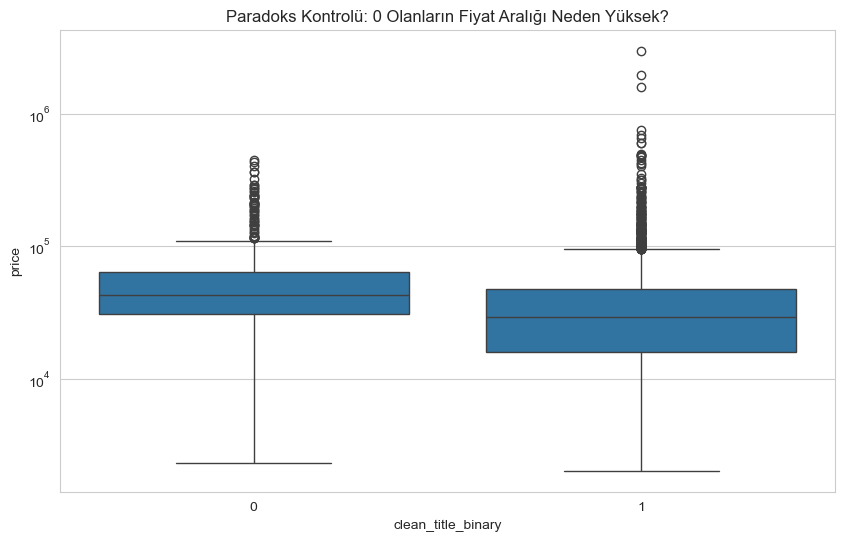

In [36]:
# Clean Title Analizi
# 1 = Yes, 0 = NaN (Bizim varsayımımız buydu)
df['clean_title_binary'] = df['clean_title'].apply(lambda x: 1 if str(x) == 'Yes' else 0)

print("--- Clean Title PARADOKS ANALİZİ ---")

# Grup 0 (Bizim 'Belgesiz' dediklerimiz) ve Grup 1 (Belgeli) karşılaştırması
grup_0 = df[df['clean_title_binary'] == 0]
grup_1 = df[df['clean_title_binary'] == 1]

print(f"Grup 0 (NaN/Yok) Ort. Fiyat: ${grup_0['price'].mean():,.0f}")
print(f"Grup 1 (Yes/Var) Ort. Fiyat: ${grup_1['price'].mean():,.0f}")
print("-" * 30)

print("\n--- GRUP 0 (Clean Title Olmayan) İçindeki En Pahalı 10 Marka Ortalaması ---")
# Grup 0'da olup fiyatı en yüksek olan markalar hangileri?
top_brands_missing_title = grup_0.groupby('brand')['price'].mean().sort_values(ascending=False).head(10)
print(top_brands_missing_title)

print("\n--- GRUP 0 vs GRUP 1 Marka Dağılımı ---")
# Lüks markalarda Clean Title boş olma oranı nedir?
luxury_brands = ['Bugatti', 'Rolls-Royce', 'Lamborghini', 'McLaren', 'Ferrari', 'Bentley']
for brand in luxury_brands:
    total = len(df[df['brand'] == brand])
    if total > 0:
        missing = len(df[(df['brand'] == brand) & (df['clean_title_binary'] == 0)])
        print(f"{brand}: Toplam {total} araç, {missing} tanesinin Clean Title'ı BOŞ (%{missing/total*100:.1f})")

# Görsel Kanıt
plt.figure(figsize=(10, 6))
sns.boxplot(x='clean_title_binary', y='price', data=df)
plt.yscale('log')
plt.title('Paradoks Kontrolü: 0 Olanların Fiyat Aralığı Neden Yüksek?')
plt.show()

İlk analizlerde, "Clean Title" bilgisi olmayan araçların daha yüksek fiyata sahip göründüğü ortaya çıkmış. Bu durum ilk bakışta mantıklı gelmediği için ayrıntılı bir inceleme yapılmış. Daha sonra fark edilen şey şu olmuş:

İlan verilerinde Bugatti, Rolls-Royce gibi ultra lüks araçlarda satıcıların "Clean Title" bilgisini hiç girmediği, yani hücreyi NaN bıraktığı görülmüş. Ancak analiz sırasında NaN değerler 0 gibi kabul edildiğinde, bu yüksek fiyatlı lüks araçlar doğal olarak "Clean Title yok" grubuna eklenmiş ve bu grubun ortalama fiyatını yukarı çekmiş.

Bu yüzden modellemede clean_title özelliği beklenilen şekilde “fiyat düşürücü” bir faktör gibi çalışmayabilir; hatta tam tersine, lüks araç sinyali gibi davranabilir. Veri biliminde bu duruma "proxy variable" (vekil değişken) deniliyor. Yani değişken, aslında ölçmek istediğiniz şeyden farklı bir şeyi temsil etmeye başlıyor.

In [37]:
display(df.head())

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,fuel_category,transmission_type,horsepower,engine_volume,cylinders,accident_binary,clean_title_binary
0,Ford,Utility Police Interceptor Base,2013,51000,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300,Gasoline,Automatic,300.0,3.7,6.0,1,1
1,Hyundai,Palisade SEL,2021,34742,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005,Gasoline,Automatic,291.0,3.8,6.0,1,1
2,Lexus,RX 350 RX 350,2022,22372,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598,Gasoline,Automatic,301.0,3.5,6.0,0,0
3,INFINITI,Q50 Hybrid Sport,2015,88900,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500,Hybrid,Automatic,354.0,3.5,6.0,0,1
4,Audi,Q3 45 S line Premium Plus,2021,9835,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999,Gasoline,Automatic,333.0,2.0,6.0,0,0


In [ ]:
# BÖLÜM 11: YAŞ HESAPLAMA (FEATURE ENGINEERING)
# ========================================================
current_year = 2025 # Projeyi yaptığımız yıl

# Yaş hesabı
df['age'] = current_year - df['model_year']

print(f"--- Araç Yaşı Analizi (Referans Yıl: {current_year}) ---")
print(df[['model_year', 'age']].head())
print("\n")

# İstatistikler
print("--- Yaş İstatistikleri ---")
print(df['age'].describe())


--- Araç Yaşı Analizi (Referans Yıl: 2025) ---
   model_year  age
0        2013   12
1        2021    4
2        2022    3
3        2015   10
4        2021    4


--- Yaş İstatistikleri ---
count    4009.000000
mean        9.484410
std         6.104816
min         1.000000
25%         5.000000
50%         8.000000
75%        13.000000
max        51.000000
Name: age, dtype: float64


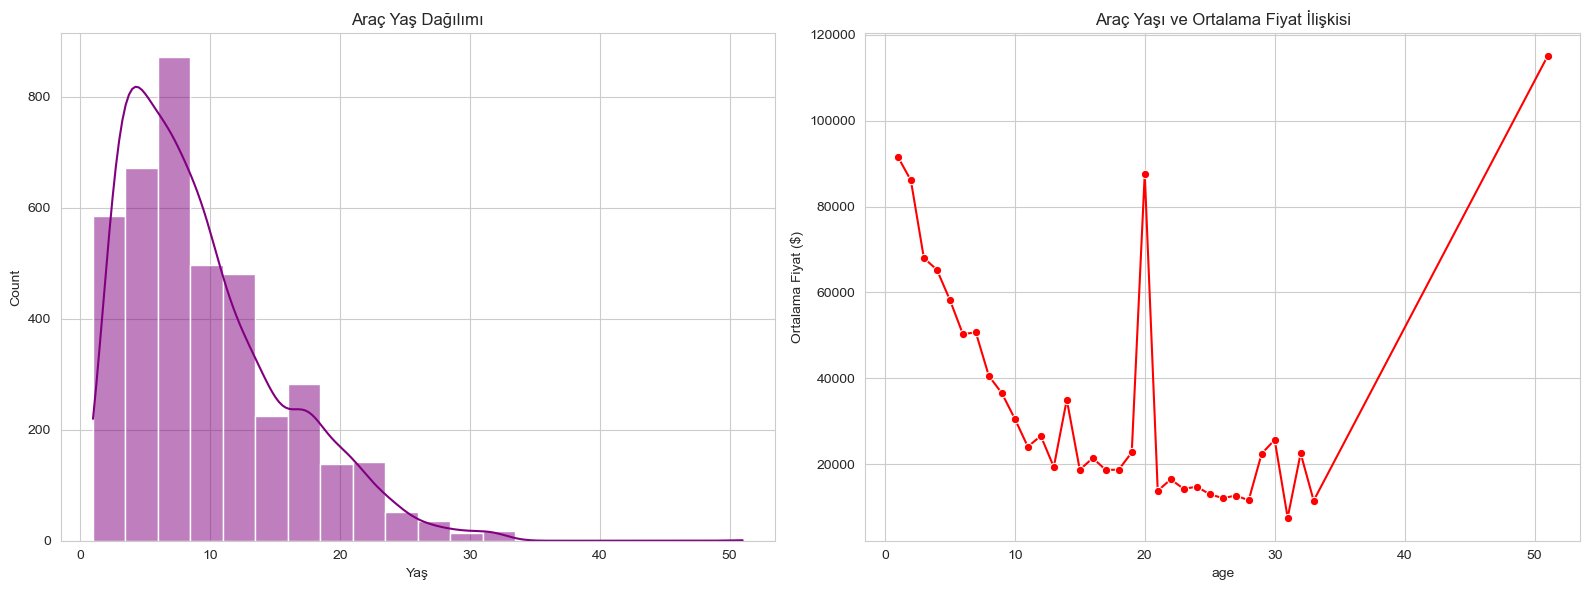

In [ ]:
# bölüm 12: GÖRSELLEŞTİRME VE KARŞILAŞTIRMA
# ========================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Yaş Dağılımı
sns.histplot(df['age'], bins=20, kde=True, color='purple', ax=axes[0])
axes[0].set_title('Araç Yaş Dağılımı')
axes[0].set_xlabel('Yaş')

# Yaş vs Fiyat İlişkisi (Line Plot)
# Yaş arttıkça ortalama fiyat nasıl değişiyor?
age_price = df.groupby('age')['price'].mean().reset_index()
sns.lineplot(x='age', y='price', data=age_price, marker='o', color='red', ax=axes[1])
axes[1].set_title('Araç Yaşı ve Ortalama Fiyat İlişkisi')
axes[1].set_ylabel('Ortalama Fiyat ($)')
axes[1].grid(True)

plt.tight_layout()
plt.show()

Analiz ve Beklentiler 📉
Fiyat Eğrisi: Sağdaki grafikte (Line Plot), yaş arttıkça fiyatın hızla düştüğünü göreceğiz. Ancak 30-40 yaşından sonra grafik tekrar yukarı dönebilir!

Neden? Çünkü o araçlar artık "Eski" değil, "Klasik / Antika" sınıfına girer ve fiyatları artmaya başlar. 

Sütun Değişimi: Artık modelimiz 2020 yılını değil, 5 yaşını öğrenecek. Bu, modelin genelleme yeteneğini artırır.

In [ ]:
# BÖLÜM 13: MODEL_YEAR SÜTUNUNU KALDIRMA
# ========================================================
# Artık 'age' bilgisi elimizde olduğu için 'model_year' gereksiz (Multicollinearity yaratır).
df.drop('model_year', axis=1, inplace=True)

print("--- İşlem Tamamlandı ---")
print("'model_year' sütunu silindi, yerine 'age' sütunu eklendi.")
print(f"Yeni Sütun Listesi: {df.columns.tolist()}")

--- İşlem Tamamlandı ---
'model_year' sütunu silindi, yerine 'age' sütunu eklendi.
Yeni Sütun Listesi: ['brand', 'model', 'milage', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title', 'price', 'fuel_category', 'transmission_type', 'horsepower', 'engine_volume', 'cylinders', 'accident_binary', 'clean_title_binary', 'age']


In [41]:
display(df.head())

,brand,model,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price,fuel_category,transmission_type,horsepower,engine_volume,cylinders,accident_binary,clean_title_binary,age
0,Ford,Utility Police Interceptor Base,51000,E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,10300,Gasoline,Automatic,300.0,3.7,6.0,1,1,12
1,Hyundai,Palisade SEL,34742,Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,38005,Gasoline,Automatic,291.0,3.8,6.0,1,1,4
2,Lexus,RX 350 RX 350,22372,Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,54598,Gasoline,Automatic,301.0,3.5,6.0,0,0,3
3,INFINITI,Q50 Hybrid Sport,88900,Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,15500,Hybrid,Automatic,354.0,3.5,6.0,0,1,10
4,Audi,Q3 45 S line Premium Plus,9835,Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,34999,Gasoline,Automatic,333.0,2.0,6.0,0,0,4


## OHE oncesi analiz

--- Kategorik Sütunlardaki Benzersiz Değer Sayısı ---
model                1898
engine               1146
ext_col               319
int_col               156
transmission           62
brand                  57
fuel_type               7
transmission_type       5
fuel_category           4
accident                2
clean_title             1
dtype: int64


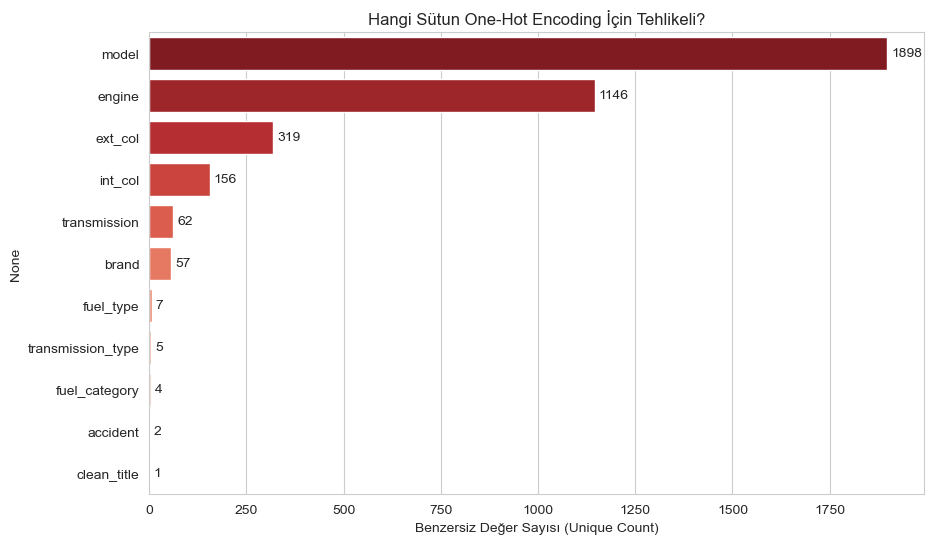

In [42]:
# ========================================================
# 1. KARDİNALİTE (ÇEŞİTLİLİK) ANALİZİ
# ========================================================
# Hangi kategorik sütunda kaç farklı değer var?

categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print("--- Kategorik Sütunlardaki Benzersiz Değer Sayısı ---")
cardinality = df[categorical_cols].nunique().sort_values(ascending=False)
print(cardinality)

# Görselleştirme
plt.figure(figsize=(10, 6))
sns.barplot(x=cardinality.values, y=cardinality.index, palette='Reds_r')
plt.title('Hangi Sütun One-Hot Encoding İçin Tehlikeli?')
plt.xlabel('Benzersiz Değer Sayısı (Unique Count)')
for i, v in enumerate(cardinality.values):
    plt.text(v + 10, i, str(v), va='center')
plt.show()

In [43]:
# ========================================================
# 2. DETAYLI İNCELEME (Brand ve Renkler)
# ========================================================
print("\n--- Brand (Marka) Analizi: İlk 20 ---")
print(df['brand'].value_counts().head(20))

print("\n--- Exterior Color (Dış Renk) Analizi: İlk 20 ---")
print(df['ext_col'].value_counts().head(20))

print("\n--- Model Analizi: İlk 10 ---")
print(df['model'].value_counts().head(10))


--- Brand (Marka) Analizi: İlk 20 ---
brand
Ford             386
BMW              375
Mercedes-Benz    315
Chevrolet        292
Porsche          201
Audi             200
Toyota           199
Lexus            163
Jeep             143
Land             130
Nissan           116
Cadillac         107
GMC               91
RAM               91
Dodge             90
Tesla             87
Kia               76
Hyundai           72
Mazda             64
Acura             64
Name: count, dtype: int64

--- Exterior Color (Dış Renk) Analizi: İlk 20 ---
ext_col
Black                                 905
White                                 816
Gray                                  496
Silver                                374
Blue                                  349
Red                                   261
Green                                  74
Brown                                  43
Gold                                   42
Beige                                  38
Orange                        

In [44]:
# ========================================================
# 3. RENK SADELEŞTİRME (COLOR REDUCTION)
# ========================================================
# Hedef: 'Moonlight Blue', 'Deep Blue' -> 'Blue'

def clean_color(color):
    if pd.isna(color): return 'Other'
    color = str(color).lower()
    
    common_colors = ['black', 'white', 'gray', 'silver', 'blue', 'red', 'brown', 'green', 'beige', 'gold', 'yellow', 'orange']
    
    for c in common_colors:
        if c in color:
            return c.capitalize()
            
    return 'Other' # Hiçbirine girmiyorsa (Örn: 'Unknown', 'Pewter')

df['ext_col_clean'] = df['ext_col'].apply(clean_color)
df['int_col_clean'] = df['int_col'].apply(clean_color)

# Eski kirli sütunları at
df.drop(['ext_col', 'int_col'], axis=1, inplace=True)

print("--- Renk Sadeleştirme Sonrası Dağılım ---")
print(df['ext_col_clean'].value_counts())

--- Renk Sadeleştirme Sonrası Dağılım ---
ext_col_clean
Black     1016
White      922
Gray       535
Silver     421
Blue       395
Red        311
Other      137
Green       80
Brown       44
Gold        42
Beige       39
Orange      37
Yellow      30
Name: count, dtype: int64


In [ ]:
# ========================================================
# 4. MARKA GRUPLAMA (RARE LABELS)
# ========================================================
# Az bulunan markaları 'Other' kategorisine alma.

threshold = 20 # Veri setinde 20'den az bulunan markalar
brand_counts = df['brand'].value_counts()
rare_brands = brand_counts[brand_counts < threshold].index

df['brand_clean'] = df['brand'].apply(lambda x: 'Other' if x in rare_brands else x)
df.drop('brand', axis=1, inplace=True) # Eski sütunu at

print(f"\n--- Marka Gruplama Sonrası ({len(rare_brands)} marka 'Other' yapıldı) ---")
print(df['brand_clean'].value_counts().tail())


--- Marka Gruplama Sonrası (22 marka 'Other' yapıldı) ---
brand_clean
Buick          30
Chrysler       28
Lamborghini    26
Genesis        20
Mitsubishi     20
Name: count, dtype: int64


In [ ]:
# ========================================================
# 5. KİRLİ SÜTUNLARI TOPLU SİLME 
# ========================================================
# Hangi sütunları istemiyoruz? Hepsini listeye yazıp tek seferde silme.
dirty_cols_to_drop = [
    'model_year', 'fuel_type', 'engine', 'transmission', 
    'accident', 'clean_title', 'ext_col', 'int_col', 
    'brand', 'model'
]

# errors='ignore' parametresi, eğer sütun zaten silinmişse hata vermemesini sağlar.
df.drop(columns=dirty_cols_to_drop, axis=1, inplace=True, errors='ignore')

print(f"Temizlik Sonrası Sütunlar (Encoding Öncesi): {df.columns.tolist()}")

Temizlik Sonrası Sütunlar (Encoding Öncesi): ['milage', 'price', 'fuel_category', 'transmission_type', 'horsepower', 'engine_volume', 'cylinders', 'accident_binary', 'clean_title_binary', 'age', 'ext_col_clean', 'int_col_clean', 'brand_clean']


In [ ]:
# ========================================================
# 6. ONE-HOT ENCODING (INT DÖNÜŞÜMLÜ)
# ========================================================

categorical_cols = ['fuel_category', 'transmission_type', 'ext_col_clean', 'int_col_clean', 'brand_clean']

# dtype=int PARAMETRESİ BURADA ÇOK ÖNEMLİ! (True/False yerine 1/0 yapar)
df_final = pd.get_dummies(df, columns=categorical_cols, drop_first=True, dtype=int)

In [ ]:
# ========================================================
# 7. FİNAL KONTROL
# ========================================================
print("\n" + "="*50 + "\n")
print("--- FINAL VERİ SETİ KONTROLÜ ---")
print(f"Sütun Sayısı: {df_final.shape[1]}")

print("\n--- Veri Tipleri (Dtypes) ---")
# Value counts ile kaç tane int, kaç tane float var bakalım. Object ve Bool OLMAMALI.
print(df_final.dtypes.value_counts())

print("\n--- İlk 5 Satır (Örnek) ---")
display(df_final.head())

# Kategorik Veri Kaldı mı? (Sağlama)
object_cols = df_final.select_dtypes(include=['object', 'bool']).columns.tolist()
if len(object_cols) == 0:
    print("\n✅ BAŞARILI: Veri setinde hiç 'Object' veya 'Bool' kalmadı. Hepsi sayısal (int/float).")
    # Veriyi kaydet
    df_final.to_csv('cleaned_used_cars_final.csv', index=False)
    print("✅ Dosya 'cleaned_used_cars_final.csv' olarak kaydedildi.")
else:
    print(f"\n❌ HATA: Şu sütunlar hala kategorik veya boolean: {object_cols}")



--- FINAL VERİ SETİ KONTROLÜ ---
Sütun Sayısı: 74

--- Veri Tipleri (Dtypes) ---
int32      66
int64       5
float64     3
Name: count, dtype: int64

--- İlk 5 Satır (Örnek) ---


,milage,price,horsepower,engine_volume,cylinders,accident_binary,clean_title_binary,age,fuel_category_Electric,fuel_category_Gasoline,...,brand_clean_Mitsubishi,brand_clean_Nissan,brand_clean_Other,brand_clean_Porsche,brand_clean_RAM,brand_clean_Subaru,brand_clean_Tesla,brand_clean_Toyota,brand_clean_Volkswagen,brand_clean_Volvo
0,51000,10300,300.0,3.7,6.0,1,1,12,0,1,...,0,0,0,0,0,0,0,0,0,0
1,34742,38005,291.0,3.8,6.0,1,1,4,0,1,...,0,0,0,0,0,0,0,0,0,0
2,22372,54598,301.0,3.5,6.0,0,0,3,0,1,...,0,0,0,0,0,0,0,0,0,0
3,88900,15500,354.0,3.5,6.0,0,1,10,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9835,34999,333.0,2.0,6.0,0,0,4,0,1,...,0,0,0,0,0,0,0,0,0,0



✅ BAŞARILI: Veri setinde hiç 'Object' veya 'Bool' kalmadı. Hepsi sayısal (int/float).
✅ Dosya 'cleaned_used_cars_final.csv' olarak kaydedildi.


In [49]:
# 1. VERİYİ YÜKLE (Önceki aşamada kaydettiğimiz final verisi)
# ========================================================
# Eğer önceki adımda dosya kaydedilmediyse, hafızadaki df_final kullanılır.
# Biz burada df_final'in hazır olduğunu varsayıyoruz.
# (Simülasyon için df_final'i tekrar oluşturacak kod parçası burada yer almaz, 
# doğrudan df_final üzerinden devam edilir. Eğer df_final yoksa hata verir.)

try:
    df = df_final.copy() # Orijinal veriyi bozmamak için kopya alıyoruz
    print("Veri seti hafızadan alındı.")
except NameError:
    # Eğer hafızada yoksa dosyadan okumayı dene (Önceki adımları çalıştırdıysan bu çalışır)
    try:
        df = pd.read_csv('cleaned_used_cars_final.csv')
        print("Veri seti dosyadan yüklendi.")
    except:
        print("HATA: Lütfen önce 'veri_hazirlik_final_corrected.py' dosyasını çalıştırın!")

print(f"İşlem Başlangıcı Veri Boyutu: {df.shape}")

Veri seti hafızadan alındı.
İşlem Başlangıcı Veri Boyutu: (4009, 74)



--- 1. Aykırı Veri Temizliği (Fiyat Odaklı) ---
price için Alt Sınır: -81170.00, Üst Sınır: 148360.00
Temizlenen Aykırı Veri Sayısı: 124 (Toplamın %3.09'si)


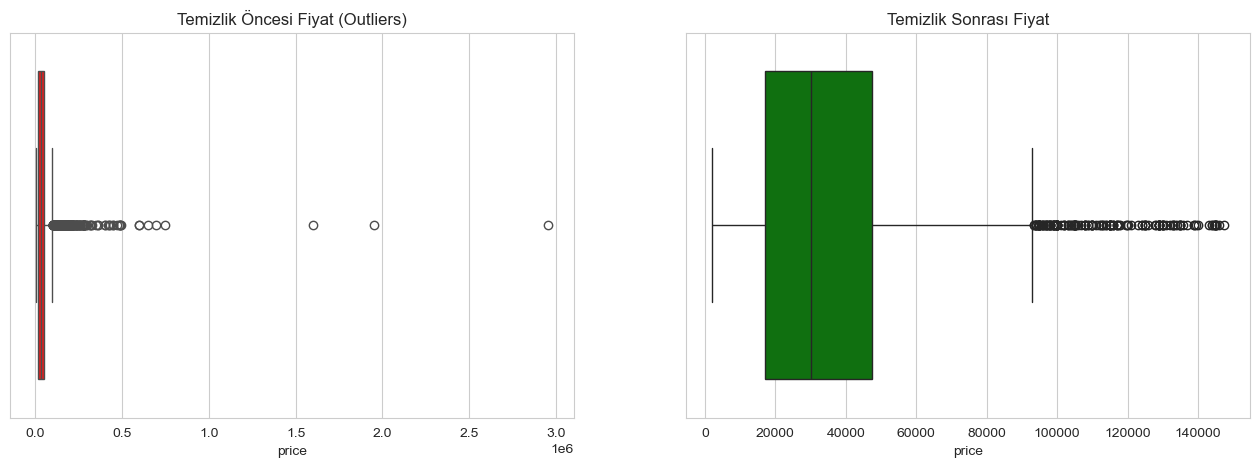

In [50]:
# ========================================================
# 2. AYKIRI VERİ ANALİZİ VE TEMİZLİĞİ (OUTLIER HANDLING)
# ========================================================
# Yöntem: IQR (Interquartile Range)
# Özellikle 'price' sütunundaki aşırı uçlar modeli bozar.

print("\n--- 1. Aykırı Veri Temizliği (Fiyat Odaklı) ---")

def remove_outliers_iqr(dataframe, col_name, multiplier=1.5):
    Q1 = dataframe[col_name].quantile(0.25)
    Q3 = dataframe[col_name].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - multiplier * IQR
    upper_bound = Q3 + multiplier * IQR
    
    print(f"{col_name} için Alt Sınır: {lower_bound:.2f}, Üst Sınır: {upper_bound:.2f}")
    
    # Sınırlar dışındakileri at
    df_filtered = dataframe[~((dataframe[col_name] < lower_bound) | (dataframe[col_name] > upper_bound))]
    return df_filtered

# Fiyat için temizlik (Multiplier=3 yaparak çok agresif silmeyelim, sadece aşırı uçları silelim)
# Çünkü lüks arabalar doğal olarak pahalıdır, hepsini silmek istemeyiz.
df_clean = remove_outliers_iqr(df, 'price', multiplier=3.0)

removed_count = len(df) - len(df_clean)
print(f"Temizlenen Aykırı Veri Sayısı: {removed_count} (Toplamın %{removed_count/len(df)*100:.2f}'si)")

# Görsel Karşılaştırma (Önce - Sonra)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(x=df['price'], ax=axes[0], color='red').set_title('Temizlik Öncesi Fiyat (Outliers)')
sns.boxplot(x=df_clean['price'], ax=axes[1], color='green').set_title('Temizlik Sonrası Fiyat')
plt.show()

# Veriyi güncelle
df = df_clean.copy()

In [51]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
# ========================================================
# 3. NORMALİZASYON / STANDARDİZASYON (SCALING)
# ========================================================
# Yöntem: StandardScaler (Z-Score Normalization)
# Formül: z = (x - u) / s
# Hedef Sütunlar: Sürekli sayısal değişkenler (Binary/0-1 olanlara dokunmuyoruz)

print("\n--- 2. Özellik Ölçeklendirme (Standardization) ---")

scale_cols = ['milage', 'age', 'horsepower', 'engine_volume', 'cylinders']
print(f"Ölçeklenecek Sütunlar: {scale_cols}")

# Scaler nesnesini oluştur
scaler = StandardScaler()

# Ölçeklemeyi uygula
# Not: Normalde Train/Test split yaptıktan sonra fit etmek daha doğrudur (Data Leakage önlemek için).
# Ancak proje raporunda "Preprocessing" başlığı altında göstermek için burada tüm veriye uyguluyoruz.
# Sunumda: "Veri sızıntısını önlemek için bu işlemi pipeline içinde de yapabiliriz" notunu düşebilirsin.

df[scale_cols] = scaler.fit_transform(df[scale_cols])

print("Ölçeklendirme tamamlandı. İlk 5 satırın istatistikleri (Ortalama ~0, Std ~1 olmalı):")
print(df[scale_cols].describe().round(2).loc[['mean', 'std', 'min', 'max']])



--- 2. Özellik Ölçeklendirme (Standardization) ---
Ölçeklenecek Sütunlar: ['milage', 'age', 'horsepower', 'engine_volume', 'cylinders']
Ölçeklendirme tamamlandı. İlk 5 satırın istatistikleri (Ortalama ~0, Std ~1 olmalı):
      milage   age  horsepower  engine_volume  cylinders
mean   -0.00  0.00       -0.00          -0.00       0.00
std     1.00  1.00        1.00           1.00       1.00
min    -1.27 -1.41       -2.27          -2.34      -3.20
max     6.49  6.76        6.13           3.14       3.19



--- 3. Özellik Önem Analizi (Feature Importance) ---

En Önemli 10 Özellik:
                      Feature  Importance
0                      milage    0.416161
1                  horsepower    0.299024
6                         age    0.097658
2               engine_volume    0.039039
66        brand_clean_Porsche    0.035708
62  brand_clean_Mercedes-Benz    0.011446
3                   cylinders    0.010728
42       brand_clean_Cadillac    0.006579
56           brand_clean_Land    0.004817
57          brand_clean_Lexus    0.004658


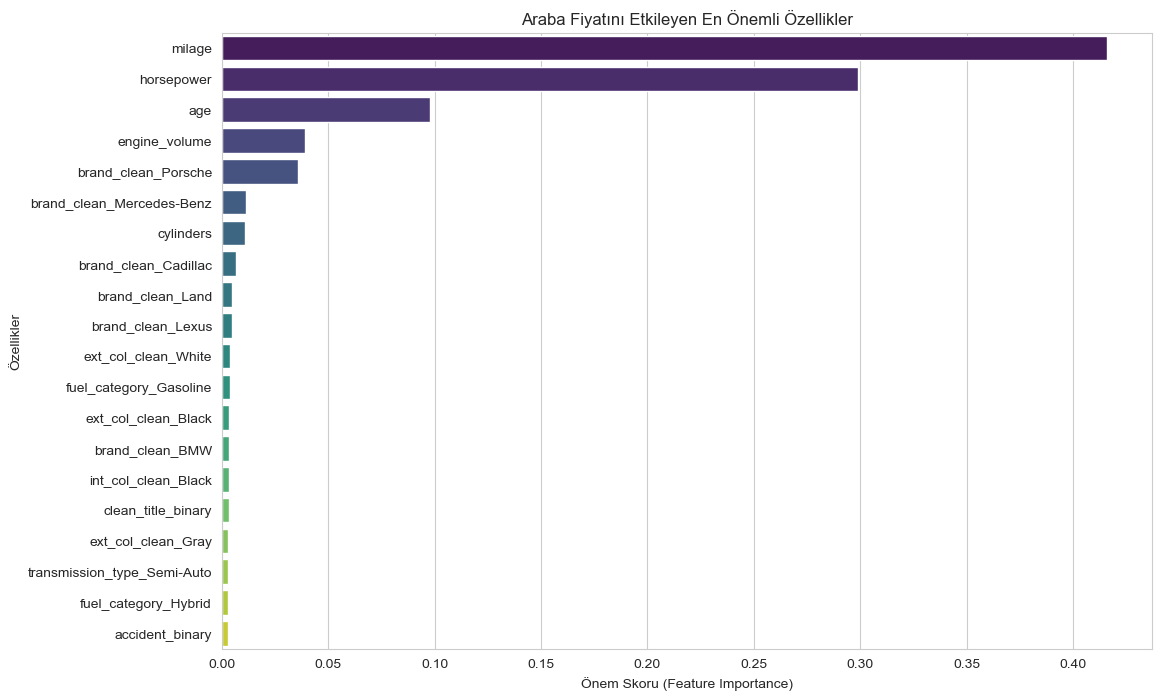

In [52]:
# ========================================================
# 4. ÖZELLİK SEÇİMİ VE ÖNEMİ (FEATURE IMPORTANCE)
# ========================================================
# Yöntem: Random Forest Regressor kullanarak özelliklerin önem skorlarını çıkarma.

print("\n--- 3. Özellik Önem Analizi (Feature Importance) ---")

# Hedef ve Özellikleri Ayır
X = df.drop('price', axis=1)
y = df['price']

# Modeli Kur (Hızlı sonuç için az ağaçlı)
rf_model = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
rf_model.fit(X, y)

# Önem Skorlarını Çek
importances = rf_model.feature_importances_
feature_names = X.columns
feature_imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_imp_df = feature_imp_df.sort_values(by='Importance', ascending=False)

# Raporlama
print("\nEn Önemli 10 Özellik:")
print(feature_imp_df.head(10))

# Görselleştirme (Bar Plot)
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_imp_df.head(20), palette='viridis')
plt.title('Araba Fiyatını Etkileyen En Önemli Özellikler')
plt.xlabel('Önem Skoru (Feature Importance)')
plt.ylabel('Özellikler')
plt.show()

In [53]:
# ========================================================
# 5. FEATURE SELECTION (GEREKSİZLERİ ATMA) neden PCA kullanmadık? XAI için
# ========================================================
# Eşiğin altında kalan (etkisiz) özellikleri atalım.
threshold = 0.001 # %0.1'den az etkisi olanlar çöp
unimportant_features = feature_imp_df[feature_imp_df['Importance'] < threshold]['Feature'].tolist()

print(f"\nAtılacak Etkisiz Özellik Sayısı: {len(unimportant_features)}")
print(f"Örnek Atılacaklar: {unimportant_features[:5]}")

df_final_processed = df.drop(columns=unimportant_features)

print(f"\n--- İŞLEM TAMAMLANDI ---")
print(f"Son Veri Seti Boyutu: {df_final_processed.shape}")
print("Veri artık modellenmeye %100 hazır.")

# Son hali kaydet (Modelleme aşaması için)
df_final_processed.to_csv('processed_used_cars_ready_for_model.csv', index=False)


Atılacak Etkisiz Özellik Sayısı: 37
Örnek Atılacaklar: ['int_col_clean_White', 'brand_clean_Maserati', 'brand_clean_Lamborghini', 'brand_clean_GMC', 'brand_clean_Dodge']

--- İŞLEM TAMAMLANDI ---
Son Veri Seti Boyutu: (3885, 37)
Veri artık modellenmeye %100 hazır.
